# Laguerre-Gaussian vortex traps: the ring phase, the topological charge and the orbital angular momentum

**Question:** How does one added term in the delay of a trap turn a point of light into a ring with a dark centre that carries orbital angular momentum, how is its charge read from the focal field, and at what charge does that reading stop being trustworthy?

- Level: 2, the method in practice. Method run: Laguerre-Gaussian vortices.
- Prerequisites: `01-fourier-optics/02-reading-a-trap-array`, for the focal field and the trap list; the weighted loop that the Laguerre-Gaussian vortex method reuses is taught in topic `03-gerchberg-saxton` and is used here as a given.
- Reading time: about 30 minutes. The notebook runs in about a minute.

## Objectives

A trap that holds a bead or an atom by its intensity gradient is a bright spot. A trap that also turns it is a ring of light with a dark centre, and the ring is made by the hologram with one added term. The product has a method for it, Laguerre-Gaussian vortices, and the case C06 uses it for a ring of sixteen vortices next to a line of plain traps. This notebook takes the method apart. By the end you can:

- write the delay of a charged trap and say which term makes the vortex and why a trap with a charge has a dark centre;
- read the charge of a trap from the focal field as the winding of its phase around the centre, and check it against the exact value of $2\pi l$;
- measure the radius of the ring and the orbital angular momentum per photon from the field, say how the radius grows with the charge, and see that the momentum per photon equals the charge;
- run the Laguerre-Gaussian vortex method on an array that mixes charged and plain traps and read the winding of every vortex;
- find the charge above which the standard check of the product stops being valid, and say whether the hologram or the check is at fault;
- call the Laguerre-Gaussian vortex method on charges and positions of your own, and know what to inspect in the output.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.forward import fft_focal_field
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet, check_in_field, snap_to_bins
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.control import m15_vortex

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C06 of `data/examples/cases.json`, the vortex ring and line: 16 traps of charge 1 on a ring and 9 plain traps on a line, on the optics of a 256 by 256 pixel SLM.

- Owner: this repository; the case is synthetic and follows the vortex traps of Polin, Ladavac, Lee, Roichman and Grier (2005).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C06.

In [2]:
# case C06: the optics and the 25 traps, of which the charged ones carry a vortex
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C06"]
setup = build.setup_of(rec)
target = build.target_of(rec)
charges = target.traps.charge
print(
    rec["case_id"],
    "|",
    len(target.traps),
    "traps |",
    int((charges != 0).sum()),
    "carry a charge, values",
    sorted(set(charges.tolist())),
)
print(
    f"SLM {setup.n_pix} x {setup.n_pix} pixels, pad {setup.pad}, one focal bin is {focal_bin_m(setup) * 1e6:.3f} um"
)

C06_vortex_ring_line | 25 traps | 16 carry a charge, values [0, 1]
SLM 256 x 256 pixels, pad 2, one focal bin is 0.499 um


## Method

### Step 1: the delay with one more term

A point trap at $(x_m, y_m, z_m)$ is made by giving the SLM pixel $j$, at $(x_j, y_j)$, the delay that a lens and a prism would give it (Di Leonardo, Ianni and Ruocco, 2007). To make that trap a vortex of charge $l_m$ the delay gets one term more, the azimuth of the pixel multiplied by the charge,

$$\Delta_j^m = \frac{\pi z_m}{\lambda f^2}\,(x_j^2 + y_j^2) + \frac{2\pi}{\lambda f}\,(x_j x_m + y_j y_m) + l_m\,\operatorname{atan2}(y_j,\, x_j),$$

with $\lambda$ the wavelength and $f$ the focal length. The first term focuses to the depth $z_m$, the second steers to the lateral position, and the third is a helical phase that advances by $2\pi l_m$ once around the axis of the SLM. A beam with the factor $e^{i l \theta}$ carries an orbital angular momentum of $l\hbar$ per photon (Allen et al., 1992), so that a particle that absorbs the power $P_{\mathrm{abs}}$ of the ring feels a torque

$$\tau = \frac{l}{\omega}\,P_{\mathrm{abs}},$$

with $\omega$ the angular frequency of the light. The helical phase also forces the field to vanish on the axis of the trap, because a phase that winds around a point has no value there; the focal pattern is a ring around a dark core, an optical vortex (Curtis and Grier, 2003). The Laguerre-Gaussian vortex method does not change the loop that makes the hologram. It runs the weighted Gerchberg-Saxton loop of Di Leonardo et al. with the charged delay in the trap field, and the quantity that it equalises across the traps is the overlap of the focal field with the vortex mode, not the intensity at the centre, which is zero by construction (Padgett and Bowman, 2011, describe the family of these modes).

### Step 2: one vortex alone, and the check the product makes of it

Take one trap at the origin and give it the charges 1, 2, 3 and $-2$ in turn. The product measures a vortex with `ring_phase_profile`: it samples the phase of the focal field at 48 points on a circle around the trap, adds the wrapped phase steps between neighbouring points, which is the winding $\oint \nabla\psi \cdot d\mathbf{s} = 2\pi l$ of a phase $\psi$ that goes around the core, and fits the line $\pm l\theta + c$ to the sampled phase to report the largest deviation from it. The circle is chosen by the function as the radius of maximum mean intensity between 0.5 and 5 bins. The acceptance row of the method ladder asks for a winding of $2\pi l$ with an error under 0.1 rad; the cell reports the winding in units of $2\pi$, the radius that the function picked and the two errors.

In [3]:
# one isolated vortex of charge 1, 2, 3 and -2 at the origin: the check of the product on the ring around it
single = {}
for charge in (1, 2, 3, -2):
    trap = Trap(0, 0.0, 0.0, 0.0, 1.0, charge)
    res = m15_vortex.run(setup, Target.from_traps(TrapSet([trap])), budget=Budget(5), rng=Rng(1))
    single[charge] = (res, m15_vortex.ring_phase_profile(res.phi, setup, trap))
    p = single[charge][1]
    print(
        f"charge {charge:+d}: winding / 2 pi {p['winding'] / (2 * np.pi):+.3f} | ring radius "
        f"{p['radius_bins']:.2f} bins | "
        f"max error {p['max_error']:.3f} rad | rms error {p['rms_error']:.3f} rad"
    )

charge +1: winding / 2 pi +1.000 | ring radius 1.50 bins | max error 0.039 rad | rms error 0.028 rad
charge +2: winding / 2 pi +2.000 | ring radius 2.50 bins | max error 0.028 rad | rms error 0.019 rad
charge +3: winding / 2 pi +3.000 | ring radius 3.25 bins | max error 0.060 rad | rms error 0.035 rad
charge -2: winding / 2 pi -2.000 | ring radius 2.50 bins | max error 0.028 rad | rms error 0.019 rad


The figure shows, for three charges, the intensity of the focal field around the trap on the top row and its phase on the bottom row.

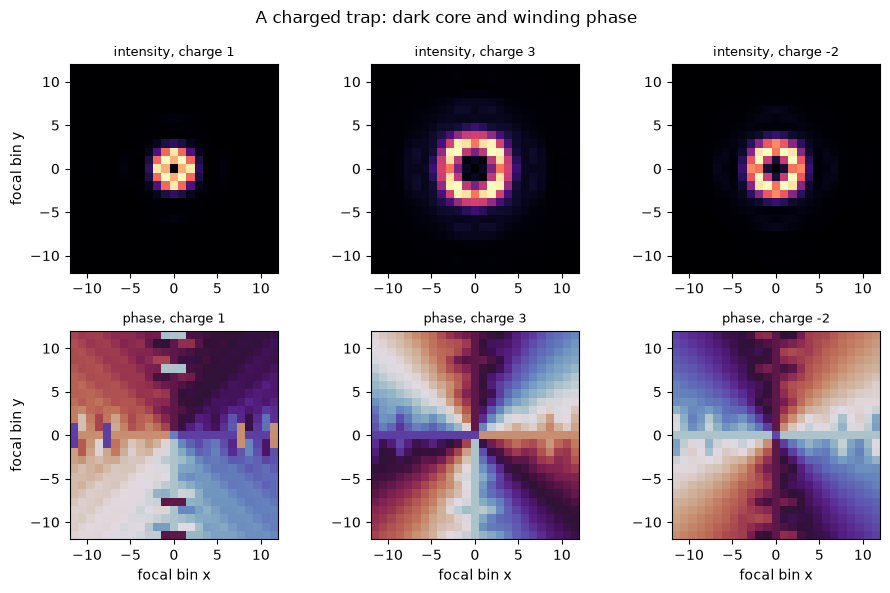

In [4]:
# the intensity and the phase of the focal field around the trap, for three charges
half = 12
fig, axes = plt.subplots(2, 3, figsize=(9.4, 6.0))
for k, charge in enumerate((1, 3, -2)):
    field = fft_focal_field(single[charge][0].phi, setup)
    c = field.shape[0] // 2
    window = field[c - half : c + half + 1, c - half : c + half + 1]
    extent = (-half, half, -half, half)
    axes[0, k].imshow(np.abs(window) ** 2, cmap="magma", origin="lower", extent=extent)
    axes[1, k].imshow(np.angle(window), cmap="twilight", origin="lower", extent=extent, vmin=-np.pi, vmax=np.pi)
    axes[0, k].set_title("intensity, charge {l}".format(l=charge), fontsize=9)
    axes[1, k].set_title("phase, charge {l}".format(l=charge), fontsize=9)
    axes[1, k].set_xlabel("focal bin x")
axes[0, 0].set_ylabel("focal bin y")
axes[1, 0].set_ylabel("focal bin y")
fig.suptitle("A charged trap: dark core and winding phase")
fig.tight_layout()
plt.show()

The winding is exact in units of $2\pi$: +1.000, +2.000, +3.000 and -2.000 for the charges 1, 2, 3 and $-2$, with the sign following the sign of the charge, and the largest deviation from the straight line $\pm l\theta + c$ is 0.039, 0.028, 0.060 and 0.028 rad, all under the 0.1 rad of the ladder. The top row of the figure shows what a charge does to the light: the intensity has a ring and an empty centre, larger for a larger charge, and the centre value is not small but exactly dark in the plot's scale. The bottom row shows what the check reads: the phase goes through all its values around the centre, as a pinwheel with $|l|$ turns, and the direction of the turn is reversed for the negative charge. What the figure does not show is the amplitude of the ring around its circumference, which should be even if the vortex is clean, and neither does the winding, which is a statement about phase alone; a ring with a bright and a dark side would pass this check.

### Step 3: the radius of the ring and the angular momentum

Two properties of the vortex can be measured from the field itself, with no reference to the check of the product. The radius of the ring is the radius at which the azimuthal mean of the intensity peaks. The orbital angular momentum per photon is computed from the complex focal field $E$,

$$\frac{L_z}{P} = \frac{\operatorname{Im}\sum E^{*}\,\bigl(x\,\partial_y E - y\,\partial_x E\bigr)}{\sum \lvert E \rvert^{2}},$$

in units of $\hbar$, with the derivatives taken in Fourier space, where the derivative of a periodic field is exact. For a field of the form $A(r)\,e^{i l\theta}$ this is exactly $l$. The field on the SLM has that form: the helical phase times a real amplitude, the Gaussian beam clipped by the square edge of the SLM, and a real amplitude with the fourfold symmetry of the square holds the angular harmonics $e^{\pm 4ik\theta}$ in pairs of equal weight, which add no net angular momentum. A two-dimensional Fourier transform commutes with rotations and so conserves the orbital angular momentum per photon, which means that the whole focal field, the light in the trap and the light outside it alike, carries $l\hbar$ per photon, and the efficiency $e$ of the run does not enter. The first cell below writes the spectral estimator as a function, and the second measures it in two ways for six charges: with spectral derivatives on the whole grid, and with central differences on the window of 81 by 81 bins around the trap, the cheaper estimator, to see whether it can be trusted. It also prints the radius of the ring and the efficiency.

In [5]:
# the orbital angular momentum per photon of a periodic complex field, with the derivatives taken in Fourier space
def lz_spectral(field):
    n_grid = field.shape[0]
    k = 2 * np.pi * np.fft.fftfreq(n_grid)
    e_y = np.fft.ifft2(1j * k[:, None] * np.fft.fft2(field))
    e_x = np.fft.ifft2(1j * k[None, :] * np.fft.fft2(field))
    x, y = np.meshgrid(np.arange(n_grid) - n_grid // 2, np.arange(n_grid) - n_grid // 2)
    return float(np.imag(np.sum(np.conj(field) * (x * e_y - y * e_x))) / np.sum(np.abs(field) ** 2))

The loop below measures the six charges: the radius of the ring, the spectral estimate through this function, and the central-difference estimate on the window of 81 bins, with the efficiency of each run printed beside them.

In [6]:
# radius of the ring from the azimuthal mean of the intensity, and the angular momentum per photon, for six charges
half = 40
axis = np.arange(-half, half + 1)
grid_x, grid_y = np.meshgrid(axis, axis)
radius_grid = np.hypot(grid_x, grid_y)
ring, lz, lz_window, eff = {}, {}, {}, {}
for charge in (1, 2, 3, 5, 8, 12):
    res = m15_vortex.run(
        setup, Target.from_traps(TrapSet([Trap(0, 0.0, 0.0, 0.0, 1.0, charge)])), budget=Budget(5), rng=Rng(1)
    )
    field = fft_focal_field(res.phi, setup)
    c = field.shape[0] // 2
    window = field[c - half : c + half + 1, c - half : c + half + 1]
    mean_ring = [
        np.mean(np.abs(window[(radius_grid >= r - 0.5) & (radius_grid < r + 0.5)]) ** 2) for r in range(1, half)
    ]
    ring[charge] = float(np.argmax(mean_ring) + 1)
    dy, dx = np.gradient(window)  # central differences on the 81-bin window
    lz_window[charge] = float(
        np.imag(np.sum(np.conj(window) * (grid_x * dy - grid_y * dx))) / np.sum(np.abs(window) ** 2)
    )
    lz[charge] = lz_spectral(field)
    eff[charge] = res.history[-1]["efficiency"]
    print(
        f"charge {charge:2d}: ring radius {ring[charge]:5.1f} bins | L_z per photon {lz[charge]:6.3f} spectral, "
        f"{lz_window[charge]:6.3f} by differences | L_z / l {lz[charge] / charge:.4f} | efficiency {eff[charge]:.4f}"
    )
exponent = np.polyfit(np.log(list(ring)), np.log(list(ring.values())), 1)[0]
print(f"radius grows as l to the power {exponent:.2f}")

charge  1: ring radius   1.0 bins | L_z per photon  1.000 spectral,  0.891 by differences | L_z / l 0.9999 | efficiency 0.8695
charge  2: ring radius   2.0 bins | L_z per photon  2.000 spectral,  1.783 by differences | L_z / l 0.9998 | efficiency 0.8695
charge  3: ring radius   3.0 bins | L_z per photon  2.999 spectral,  2.673 by differences | L_z / l 0.9997 | efficiency 0.8695
charge  5: ring radius   5.0 bins | L_z per photon  4.998 spectral,  4.451 by differences | L_z / l 0.9996 | efficiency 0.8695
charge  8: ring radius   7.0 bins | L_z per photon  7.991 spectral,  7.107 by differences | L_z / l 0.9989 | efficiency 0.8695
charge 12: ring radius   9.0 bins | L_z per photon 11.973 spectral, 10.615 by differences | L_z / l 0.9977 | efficiency 0.8695
radius grows as l to the power 0.90


The left panel plots the radius of the ring against the charge and the right panel the angular momentum per photon, with the line $l\,e$ that the efficiency predicts.

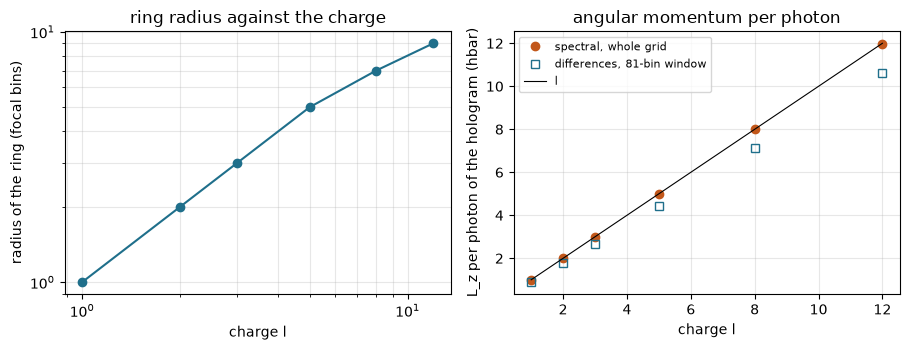

In [7]:
# the radius of the ring and the angular momentum per photon against the charge
ls = np.array(list(ring))
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.6))
a.loglog(ls, [ring[l] for l in ls], "o-", color="#1f6f8b")
a.set_xlabel("charge l")
a.set_ylabel("radius of the ring (focal bins)")
a.set_title("ring radius against the charge")
a.grid(True, which="both", alpha=0.3)
b.plot(ls, [lz[l] for l in ls], "o", color="#c2571a", label="spectral, whole grid")
b.plot(ls, [lz_window[l] for l in ls], "s", mfc="none", color="#1f6f8b", label="differences, 81-bin window")
b.plot(ls, ls, "k-", linewidth=0.8, label="l")
b.set_xlabel("charge l")
b.set_ylabel("L_z per photon of the hologram (hbar)")
b.set_title("angular momentum per photon")
b.legend(fontsize=8)
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The ring grows with the charge, from 1 bin at $l = 1$ to 9 bins at $l = 12$, and the fitted law is $r \propto l^{0.90}$ between those. That exponent is not the 1/2 of a Laguerre-Gaussian mode of fixed waist, whose ring has the radius $\sqrt{|l|/2}\,w$; a helical phase put on an SLM that is lit by a Gaussian beam makes a ring that grows faster than that, because the focal ring is the Fourier transform of a helical phase that is also getting steeper at the edge of the beam. The exponent is measured on integer radii with the peak found at one-bin resolution, so it is good to about a tenth. On the right the angular momentum per photon of the whole focal field, measured with spectral derivatives, is 1.000 at $l = 1$ and 11.973 at $l = 12$: the filled circles lie on the line $L_z=l$, and the printed ratio $L_z/l$ falls from 0.9999 to 0.9977, a small shortfall that grows with the charge and whose cause was not traced further. It is not the efficiency of 0.8695, which the printed lines show unchanged across charges and which does not enter. The open squares are the central-difference estimate on the 81-bin window, 0.891 at $l = 1$ and 10.615 at $l = 12$, about 11 percent under the line at every charge, a bias of the estimator on a grid with only $\mathrm{pad}=2$ bins per resolution cell, not a property of the light, and it is near the efficiency only by coincidence. The reading is that every photon of the hologram carries $l\hbar$ on average, those that reach the trap and those that do not, and that the torque on a bead is $l/\omega$ times the power it absorbs from the ring, which depends on how much of the ring's light the bead intercepts and not on the efficiency as such. The window of 40 bins contains every ring here; it would not contain the larger rings of the next section, and the figure does not say anything about the stability of a bead in a ring, which depends on the gradient force and not on the angular momentum alone.

### Step 4: charged and plain traps in one hologram

The method exists to put vortices in the same hologram as the other traps. Case C06 asks for 16 traps of charge 1 on a ring and 9 plain traps on a line. The cell runs the Laguerre-Gaussian vortex method on the whole target for 20 iterations, which is the budget of the array test of the method, reads the winding and the largest phase error of every charged trap with the same function as before, and reports how equal the powers of the 25 traps are, which is what the weighted loop works to achieve.

In [8]:
# Laguerre-Gaussian vortices on the whole array of case C06, 20 iterations: the winding of every charged trap and
# the equality of its power
array = m15_vortex.run(setup, target, budget=Budget(20), rng=Rng(1))
vortices = [t for t in array.meta["traps"] if t.charge != 0]
profiles = [m15_vortex.ring_phase_profile(array.phi, setup, t) for t in vortices]
winding = np.array([p["winding"] / (2 * np.pi) for p in profiles])
errors = np.array([p["max_error"] for p in profiles])
power = np.abs(array.fields) ** 2
print(
    f"{len(vortices)} charged traps: winding / 2 pi between {winding.min():.3f} and {winding.max():.3f} | "
    f"largest error {errors.max():.3f} rad"
)
print(
    f"relative spread of the 25 trap powers {100 * power.std() / power.mean():.3f} % | efficiency {power.sum():.4f}"
)

16 charged traps: winding / 2 pi between 1.000 and 1.000 | largest error 0.205 rad
relative spread of the 25 trap powers 0.147 % | efficiency 0.7008


All 16 vortices wind between 1.000 and 1.000 turns, and the largest phase error among them is 0.205 rad. That is above the 0.1 rad of the isolated vortex and a little above the 0.2 rad that the product's own array test allows for four vortices, which is a different array, so the comparison is a hint and not a failure: with 25 traps in one hologram the field around each is perturbed by its neighbours, and the looser bound for arrays exists for that reason. The powers of the 25 traps agree to a relative spread of 0.147 percent at an efficiency of 0.7008, so the weighted loop equalises charged and plain traps together. The statement that the figures support is limited to this array and this budget; it does not say how far apart two vortices must be before their rings overlap, which is a question about the radius law of the previous step and not about the winding.

### Where it breaks: the charge at which the check stops being valid

The check of the product reads the phase at 48 points on a circle. A winding is the sum of the wrapped phase steps between neighbouring points, and a wrapped step is only the true step if the true step is below $\pi$ in size. For a phase that advances by $2\pi l$ around $N$ points the step is $2\pi l / N$, so the check is valid only for

$$\lvert l \rvert < \frac{N}{2},$$

which for $N = 48$ is a charge of 23 or less (Nyquist's condition applied to the azimuth). Above it the sum of wrapped steps aliases, and returns the winding folded into the range from $-N/2$ to $N/2$, that is $l-N$ for $l$ between 25 and 47, and at $l=24$, where the step is exactly $\pi$, the sign of the fold is not defined. The question is whether the hologram also fails there, or only the check. The cell separates them. For charges from 1 to 40 it makes the hologram, finds the radius of the ring from the intensity, and reads the winding at that radius with the 48 points of the product and then with 192, setting the constant of the module for the second read (the module has no parameter for the number of points, so the cell sets the constant and restores it); a hologram that is right and a check that is not will agree at 192 and disagree at 48.

In [9]:
# the same check at larger charges, with the ring read at its measured radius, by the 48 points of the product and
# by 192 (the module has no parameter for the number of points, so the cell sets its constant and restores it)
wound, radii = {}, {}
try:
    for points in (48, 192):
        m15_vortex._N_RING = points
        for charge in (1, 8, 16, 24, 32, 40):
            trap = Trap(0, 0.0, 0.0, 0.0, 1.0, charge)
            res = m15_vortex.run(setup, Target.from_traps(TrapSet([trap])), budget=Budget(5), rng=Rng(1))
            field = fft_focal_field(res.phi, setup)
            c = field.shape[0] // 2
            window = field[c - 60 : c + 61, c - 60 : c + 61]
            axis_w = np.arange(-60, 61)
            radius_w = np.hypot(*np.meshgrid(axis_w, axis_w))
            mean_w = [np.mean(np.abs(window[(radius_w >= r - 0.5) & (radius_w < r + 0.5)]) ** 2) for r in range(1, 60)]
            radii[charge] = float(np.argmax(mean_w) + 1)
            wound[charge, points] = m15_vortex.ring_phase_profile(res.phi, setup, trap, radius_bins=radii[charge])[
                "winding"
            ] / (2 * np.pi)
finally:
    m15_vortex._N_RING = 48
for charge in (1, 8, 16, 24, 32, 40):
    radius = radii[charge]
    print(
        f"charge {charge:2d}: ring at {radius:4.1f} bins | winding / 2 pi {wound[charge, 48]:6.2f} with 48 points, "
        f"{wound[charge, 192]:6.2f} with 192"
    )

charge  1: ring at  1.0 bins | winding / 2 pi   1.00 with 48 points,   1.00 with 192
charge  8: ring at  7.0 bins | winding / 2 pi   8.00 with 48 points,   8.00 with 192
charge 16: ring at 13.0 bins | winding / 2 pi  16.00 with 48 points,  16.00 with 192
charge 24: ring at 18.0 bins | winding / 2 pi   8.00 with 48 points,  24.00 with 192
charge 32: ring at 23.0 bins | winding / 2 pi -16.00 with 48 points,  32.00 with 192
charge 40: ring at 28.0 bins | winding / 2 pi  -8.00 with 48 points,  40.00 with 192


The figure plots the winding read with 48 and with 192 points against the charge, with the line of the exact value.

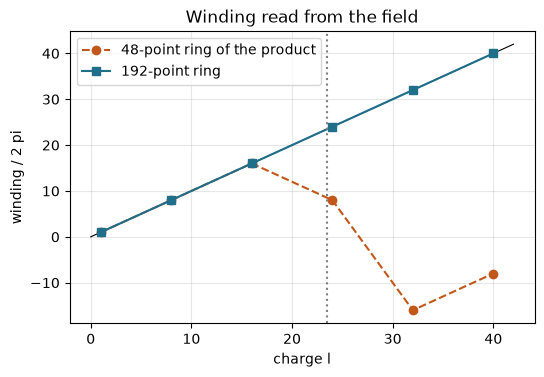

In [10]:
# the winding in turns, read with the 48 points of the product and with 192, against the charge
charges_swept = sorted({c for c, _ in wound})
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot([0, 42], [0, 42], "k-", linewidth=0.8)
ax.plot(
    charges_swept,
    [wound[c, 48] for c in charges_swept],
    "o--",
    color="#c2571a",
    label="48-point ring of the product",
)
ax.plot(charges_swept, [wound[c, 192] for c in charges_swept], "s-", color="#1f6f8b", label="192-point ring")
ax.axvline(23.5, color="gray", linestyle=":")
ax.set_xlabel("charge l")
ax.set_ylabel("winding / 2 pi")
ax.set_title("Winding read from the field")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

Up to the charge 16 the two reads agree with the exact value: 16.00 with 48 points and 16.00 with 192 at $l = 16$. At $l = 24$, where the step per point is exactly $\pi$, the 48-point read gives 8.00 turns and at 32 it gives -16.00, while the 192-point read gives 24.00 and 32.00, and at 40 it still gives 40.00 against the -8.00 of the short ring. So the hologram is right to the largest charge tried and the check is the thing that fails, at the charge predicted by $N/2$. The dotted line marks that limit, and the ring radius grows to 28 bins at $l = 40$, so a user who raises the charge must also enlarge the window in which the ring is searched: the default search stops at 5 bins and would not find the ring at all beyond a charge of about 5, which is why this cell passes the measured radius. The figure checks the phase of one isolated trap with a budget of 5 iterations; it does not show the equality of the power for large charges, nor whether a ring of 18 or more bins fits in a hologram that also has other traps.

### Use it on your own data

The Laguerre-Gaussian vortex method takes a `Target` of traps in which at least one `Trap` has a non-zero `charge`, or any target together with the keyword `charge`, which gives that charge to every trap. A trap is `Trap(id, x_m, y_m, z_m, weight, charge)` with the position in metres, the weight relative to the others and an integer charge, positive or negative; the sign is the direction of the circulation. The conditions are those of every point-trap method, the positions inside the field of view of the setup, which `check_in_field` enforces, and on the focal bins, which `snap_to_bins` does, plus one of the vortices: the rings have a radius that grows with the charge as the previous steps showed, so the traps must be farther apart than the sum of their ring radii, or the rings merge. What to inspect in the output is the winding of each charged trap, read with `ring_phase_profile` at the radius of its ring when the charge is above about 5, the equality of the powers in `res.fields`, and the efficiency.

The cell puts three vortices of charges $+2$, $-1$ and $+3$ and one plain trap 12 um apart, runs 20 iterations, and reads the winding of each vortex.

In [11]:
# your own traps: charges +2, -1 and +3 and a plain trap, 12 um apart, 20 iterations
own = TrapSet(
    [
        Trap(0, -12e-6, 0.0, 0.0, 1.0, 2),
        Trap(1, 0.0, 0.0, 0.0, 1.0, -1),
        Trap(2, 12e-6, 0.0, 0.0, 1.0, 3),
        Trap(3, 0.0, 12e-6, 0.0, 1.0, 0),
    ]
)
own = snap_to_bins(setup, own)
check_in_field(setup, own)
mine = m15_vortex.run(setup, Target.from_traps(own), budget=Budget(20), rng=Rng(1))
own_winding = {}
for trap in own:
    if trap.charge != 0:
        p = m15_vortex.ring_phase_profile(mine.phi, setup, trap)
        own_winding[trap.id] = (trap.charge, p["winding"] / (2 * np.pi), p["max_error"])
        print(
            f"trap {trap.id} charge {trap.charge:+d}: winding / 2 pi {own_winding[trap.id][1]:+.3f} | "
            f"max error {p['max_error']:.3f} rad"
        )
own_power = np.abs(mine.fields) ** 2
print("power of the four traps relative to their mean", np.round(own_power / own_power.mean(), 3).tolist())

trap 0 charge +2: winding / 2 pi +2.000 | max error 0.062 rad
trap 1 charge -1: winding / 2 pi -1.000 | max error 0.076 rad
trap 2 charge +3: winding / 2 pi +3.000 | max error 0.136 rad
power of the four traps relative to their mean [1.0, 1.0, 1.0, 1.0]


The figure shows the focal intensity around the four traps with their positions marked.

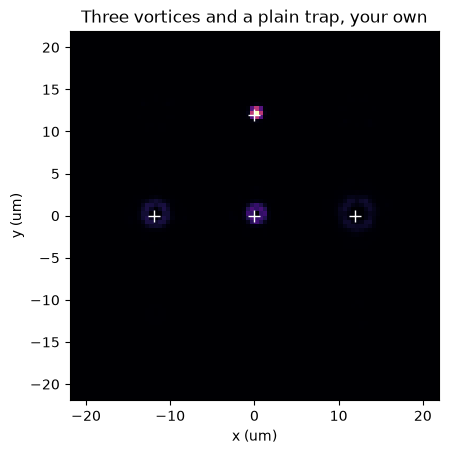

In [12]:
# the focal intensity around your four traps, with the traps marked
field = fft_focal_field(mine.phi, setup)
c = field.shape[0] // 2
reach = int(round(22e-6 / focal_bin_m(setup)))
extent = np.array([-reach, reach, -reach, reach]) * focal_bin_m(setup) * 1e6
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.imshow(
    np.abs(field[c - reach : c + reach, c - reach : c + reach]) ** 2, cmap="magma", origin="lower", extent=extent
)
ax.plot(own.x_m * 1e6, own.y_m * 1e6, "+", color="white", markersize=9)
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("Three vortices and a plain trap, your own")
plt.show()

The three vortices wind +2.000, -1.000 and +3.000 turns for the charges $+2$, $-1$ and $+3$, with phase errors of 0.062, 0.076 and 0.136 rad, so the signs and the magnitudes are read back correctly, and the figure shows three rings of different sizes with dark centres and one bright point, the plain trap. The charge of $+3$ makes the largest ring and the charge of $-1$ the smallest, as the radius law says. The powers of the four traps relative to their mean are 1.000, 1.000, 1.000 and 1.000, so the hologram is as equal in power as the weighted loop can make it in 20 iterations. If the windings were off by whole turns the first suspect would be a ring radius outside the default search, and if the powers were uneven, a budget too short or rings that overlap. The run does not tell whether the rings are clean around their circumference, and it does not tell how a particle will behave in them; both need the field and a model of the object, which the dynamics topic starts to supply.

## Results

**Answer:** One added term in the delay, the azimuth times the charge, turns a point trap into a ring with a dark centre, and the charge is read back as the winding of the focal phase around the centre: +3.000 turns for $l = 3$ and -2.000 for $l = -2$, with phase errors under 0.1 rad. The ring has a radius of 1 bin at $l = 1$ and 9 bins at $l = 12$, and the whole focal field carries $l\hbar$ per photon, measured as 11.973 at $l = 12$ with spectral derivatives, where central differences on an 81-bin window give 10.615, an 11 percent shortfall of the estimator. In the array of case C06 all 16 vortices wind between 1.000 and 1.000 turns, with a largest phase error of 0.205 rad. The standard check of the product, which reads the phase at 48 points, stops being valid at the charge 24: at $l = 32$ it reports -16.00 turns where the 192-point read gives 32.00, so the hologram is right and the check is not. What the notebook did not test is the equality of the power at large charges or the behaviour of a particle in the ring.

## Summary

- A charged trap adds the azimuth times the charge to the delay of the point-trap model, and the hologram makes a ring with a dark centre whose phase winds by $2\pi l$.
- The winding is exact for the isolated vortices of charge 1, 2, 3 and $-2$ and the phase error stays under 0.1 rad; in an array of 16 vortices and 9 plain traps it reaches 0.2 rad.
- The radius of the ring grows faster than $\sqrt{|l|}$, and the whole focal field carries the angular momentum $l\hbar$ per photon, measured with spectral derivatives, where a central-difference estimate on a small window falls 11 percent short.
- The 48-point check of the product aliases from the charge 24 and the hologram does not; a charge above about 5 needs the ring radius passed to `ring_phase_profile`.
- A set of charged traps of your own needs the field-of-view check, the snap to bins and rings that do not overlap; read the winding of each vortex and the equality of the powers.

## References

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin, Ladavac, Lee, Roichman and Grier (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Allen, Beijersbergen, Spreeuw and Woerdman (1992). Orbital angular momentum of light and the transformation of Laguerre-Gaussian laser modes. Physical Review A 45, 8185. https://doi.org/10.1103/PhysRevA.45.8185
- Curtis and Grier (2003). Structure of optical vortices. Physical Review Letters 90, 133901. https://doi.org/10.1103/PhysRevLett.90.133901
- Padgett and Bowman (2011). Tweezers with a twist. Nature Photonics 5, 343. https://doi.org/10.1038/nphoton.2011.81